# Q4 - Player features

Build one row per player with features that describe how he plays and how he behaves, to be reused for churn analysis (`still_active`) and modelling.

Feature families:
1. **Activity and tenure**: volume, rhythm, sessions, gaps.
2. **Performance**: win rate, K/D, kills and deaths profile, early vs late trend, streaks.
3. **Behaviour**: what a player does after a loss / a win, when he plays.
4. **Game modes and lobbies**: mode mix, lobby size.
5. **Social**: teammates and opponents (diversity, repeat partners).
6. **Composite scores**: an Elo rating built on victories and an addiction index.

Choices (kept from the previous notebooks):
- Win/lose uses only `victory` in `TRUE` / `FALSE`; `draw` / `other` are neither a win nor a loss and break a streak.
- K/D uses only rows with non-null `kills` and `death`.
- All game modes are kept. All players are kept (no minimum number of matches): `matches` is a column, filter on it downstream. Rates computed on few matches are noisy.
- A **session** is a run of matches separated by less than 30 minutes.
- Reference date for recency features = last match of the whole dataset.

In [1]:
from datetime import timedelta
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns

sns.set_theme(style='whitegrid')
pl.Config.set_tbl_cols(40)
pl.Config.set_tbl_rows(40)

DATA_PATH: Path = Path('playersmatches_test - playersmatches_test.csv')
OUTPUT_PATH: Path = Path('player_features.parquet')
NUM_COLUMNS: list[str] = ['kills', 'death', 'playernb_in_match']
MODES: list[str] = ['PVP_RANKED', 'PVP_UNRANKED', 'PVP']  # OPERATIONS (5 rows) has no feature of its own
SESSION_GAP_MIN: int = 30  # two matches closer than this belong to the same session
N_EARLY: int = 5  # onboarding window (first matches)
N_EDGE: int = 10  # first / last N matches to measure a trend (needs 2 * N_EDGE matches)
MIN_DECIDED_MODE: int = 5  # minimum decided matches to give a per-mode win rate / K/D

df_raw: pl.DataFrame = pl.read_csv(
    DATA_PATH,
    infer_schema=False,
    null_values=['null'],
).with_columns(
    pl.col('match_datetime').str.to_datetime(time_zone='UTC', strict=False),
    pl.col(*NUM_COLUMNS).cast(pl.Int64, strict=False),
    (pl.col('still_active') == 'TRUE').alias('still_active'),
)
REF_DATE = df_raw['match_datetime'].max()
print(df_raw.shape, '| players:', df_raw['playerid'].n_unique(), '| reference date:', REF_DATE)

FileNotFoundError: Le fichier spécifié est introuvable. (os error 2): playersmatches_test - playersmatches_test.csv

## 0. Match-level preparation

Everything is derived from the match table sorted by player and time: previous result, gap with the previous match, session id, rank of the match in the player's history.

In [ ]:
df_pm: pl.DataFrame = (
    df_raw.sort('playerid', 'match_datetime', 'matchid')
    .with_columns(
        pl.when(pl.col('victory') == 'TRUE').then(1).when(pl.col('victory') == 'FALSE').then(0).cast(pl.Int8).alias('win'),
        pl.col('match_datetime').diff().over('playerid').dt.total_seconds().alias('gap_s'),
        (pl.int_range(pl.len()).over('playerid') + 1).alias('match_n'),
        pl.len().over('playerid').alias('n_total'),
        (pl.col('match_datetime') - pl.col('match_datetime').min().over('playerid')).dt.total_seconds().truediv(86400).alias('days_since_first'),
        pl.col('match_datetime').dt.hour().alias('hour'),
        (pl.col('match_datetime').dt.weekday() >= 6).alias('is_weekend'),
        pl.col('teammateid').str.split(',').list.len().fill_null(0).alias('n_teammates'),
        (pl.col('kills') >= pl.col('death')).alias('kills_ge_deaths'),
    )
    .with_columns(
        (pl.col('gap_s').is_null() | (pl.col('gap_s') > SESSION_GAP_MIN * 60)).alias('new_session'),
        pl.col('win').shift(1).over('playerid').alias('prev_win'),
        (pl.col('n_total') - pl.col('match_n') + 1).alias('match_n_desc'),
        (pl.col('hour') < 6).alias('is_night'),  # UTC: the player time zone is unknown
    )
    .with_columns(pl.col('new_session').cum_sum().over('playerid').alias('session_id'))
)
print('still_active constant per player:', df_pm.group_by('playerid').agg(pl.col('still_active').n_unique().alias('n')).filter(pl.col('n') > 1).height == 0)
df_pm.select('playerid', 'match_datetime', 'win', 'gap_s', 'match_n', 'new_session', 'session_id', 'prev_win').head(8)

still_active constant per player: True


playerid,match_datetime,win,gap_s,match_n,new_session,session_id,prev_win
str,"datetime[μs, UTC]",i8,i64,i64,bool,u32,i8
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 16:49:44.910 UTC,1,null,1,true,1,null
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 17:27:49.456 UTC,1,2284,2,true,2,1
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 18:05:48.986 UTC,1,2279,3,true,3,1
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 18:25:00.127 UTC,1,1151,4,false,3,1
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 19:55:59.067 UTC,1,5458,5,true,4,1
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 20:08:06.487 UTC,1,727,6,false,4,1
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 20:24:46.239 UTC,1,999,7,false,4,1
"""00229b3f-4e74-4e8d-b6ce-37df9a…",2025-03-07 20:45:58.396 UTC,1,1272,8,false,4,1


## 1. Activity and tenure

`days_since_last_match`, `matches_last_30d` and `matches_last_90d` are **recency** features: they are almost a definition of "no longer active", so they leak the target if used to predict `still_active`. They are kept in the table but tagged (see the feature groups below).

In [ ]:
df_activity: pl.DataFrame = (
    df_pm.group_by('playerid')
    .agg(
        pl.col('still_active').first(),
        pl.len().alias('matches'),
        pl.col('match_datetime').min().alias('first_match'),
        pl.col('match_datetime').max().alias('last_match'),
        pl.col('match_datetime').dt.date().n_unique().alias('active_days'),
        pl.col('match_datetime').dt.truncate('1w').n_unique().alias('active_weeks'),
        pl.col('match_datetime').dt.truncate('1w').min().alias('first_week'),
        pl.col('match_datetime').dt.truncate('1w').max().alias('last_week'),
        pl.col('session_id').max().alias('sessions'),
        # gaps between two sessions, in hours (gap inside a session is not a "break")
        (pl.col('gap_s').filter(pl.col('new_session')).median() / 3600).alias('median_break_h'),
        (pl.col('gap_s').max() / 86400).alias('max_gap_days'),
        (pl.col('days_since_first') < 30).sum().alias('matches_first_30d'),
        (pl.col('match_datetime') >= REF_DATE - timedelta(days=30)).sum().alias('matches_last_30d'),
        (pl.col('match_datetime') >= REF_DATE - timedelta(days=90)).sum().alias('matches_last_90d'),
    )
    .with_columns(
        ((pl.col('last_match') - pl.col('first_match')).dt.total_seconds() / 86400).alias('tenure_days'),
        ((pl.lit(REF_DATE) - pl.col('last_match')).dt.total_seconds() / 86400).alias('days_since_last_match'),
    )
    .with_columns(
        (pl.col('matches') / pl.col('active_days')).alias('matches_per_active_day'),
        (pl.col('matches') / pl.col('sessions')).alias('matches_per_session'),
        (pl.col('sessions') / (pl.col('tenure_days') / 7 + 1)).alias('sessions_per_week'),
        # share of the calendar weeks of his lifespan in which he played at least once (regularity)
        (pl.col('active_weeks') / ((pl.col('last_week') - pl.col('first_week')).dt.total_days() / 7 + 1)).alias('active_weeks_share'),
    )
    .drop('first_week', 'last_week')
)
assert df_activity['active_weeks_share'].max() <= 1
print(df_activity.height, 'players')
df_activity.drop('playerid', 'first_match', 'last_match').describe()

840 players


statistic,still_active,matches,active_days,active_weeks,sessions,median_break_h,max_gap_days,matches_first_30d,matches_last_30d,matches_last_90d,tenure_days,days_since_last_match,matches_per_active_day,matches_per_session,sessions_per_week,active_weeks_share
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",840.0,840.0,840.0,840.0,840.0,699.0,748.0,840.0,840.0,840.0,840.0,840.0,840.0,840.0,840.0,840.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,141.0,92.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""mean""",0.419048,113.967857,24.677381,8.453571,55.808333,108.700149,59.012875,33.660714,8.988095,24.860714,122.752322,124.97531,3.555168,2.046119,2.750326,0.678696
"""std""",null,214.27,38.989097,10.331697,102.223237,501.835832,70.208853,52.868112,28.75402,69.15963,131.920978,111.315029,2.155494,0.982366,2.914245,0.330617
"""min""",0.0,1.0,1.0,1.0,1.0,0.501944,0.002801,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.050733,0.042553
"""25%""",null,5.0,2.0,2.0,3.0,3.171944,4.973171,3.0,0.0,0.0,2.55816,16.953044,2.0,1.456522,0.998705,0.363636
"""50%""",null,28.0,8.0,4.0,12.0,13.792778,28.005775,10.0,0.0,0.0,55.962731,99.826505,3.318182,1.886792,1.653318,0.75
"""75%""",null,111.0,29.0,11.0,56.0,26.401389,93.980637,42.0,1.0,14.0,246.17309,222.655093,4.595041,2.309278,3.502061,1.0
"""max""",1.0,1974.0,276.0,53.0,980.0,6454.923056,330.938785,438.0,374.0,695.0,363.910648,363.729144,14.075,8.0,23.596347,1.0


Observation:
- Very uneven players: median of 28 matches but mean of 114 (max 1,974); **31% of the players have a lifespan under 7 days** and 92 players have a single match.
- Typical player: 8 active days, 12 sessions, 1.7 sessions per week, 1.9 matches per session (longest session: 5 matches, max 38).
- Breaks between sessions are long (median 14 h) and some players come back after a long pause (median longest gap 28 days, max 331): a gap alone is not churn.
- `days_since_last_match`, `matches_last_30d` and `matches_last_90d` are recency features: **they leak `still_active`**, to keep out of any churn model.

## 2. Performance

K/D = total kills / total deaths (undefined without any death), as in the previous notebook. Trends compare the first and last 10 matches and are only defined for players with 20+ matches (no overlap between the two windows). `share_zero_kill` and `share_kills_ge_deaths` add a per-match view that a global ratio hides.

In [ ]:
def kd_expr(mask: pl.Expr) -> pl.Expr:
    deaths = pl.col('death').filter(mask).sum()
    return pl.when(deaths > 0).then(pl.col('kills').filter(mask).sum() / deaths)


df_perf: pl.DataFrame = (
    df_pm.group_by('playerid')
    .agg(
        pl.col('win').count().alias('decided'),
        pl.col('win').sum().alias('wins'),
        pl.col('win').mean().alias('win_rate'),
        pl.col('kills').count().alias('matches_with_kd'),
        pl.col('kills').sum().alias('kills_sum'),
        pl.col('death').sum().alias('death_sum'),
        pl.col('kills').mean().alias('kills_per_match'),
        pl.col('death').mean().alias('deaths_per_match'),
        pl.col('kills').std().alias('kills_std'),
        pl.col('death').std().alias('deaths_std'),
        pl.col('kills').max().alias('kills_max'),
        (pl.col('kills') == 0).mean().alias('share_zero_kill'),
        pl.col('kills_ge_deaths').mean().alias('share_kills_ge_deaths'),
        pl.col('win').filter(pl.col('match_n') <= N_EARLY).mean().alias('win_rate_early'),
        kd_expr(pl.col('match_n') <= N_EARLY).alias('kd_early'),
        pl.col('win').filter(pl.col('match_n') <= N_EDGE).mean().alias('win_rate_first'),
        pl.col('win').filter(pl.col('match_n_desc') <= N_EDGE).mean().alias('win_rate_last'),
        kd_expr(pl.col('match_n') <= N_EDGE).alias('kd_first'),
        kd_expr(pl.col('match_n_desc') <= N_EDGE).alias('kd_last'),
        pl.col('win').last().alias('last_result_win'),
    )
    .with_columns(
        pl.when(pl.col('death_sum') > 0).then(pl.col('kills_sum') / pl.col('death_sum')).alias('kd_ratio'),
    )
    .drop('kills_sum', 'death_sum')
)

# streaks (all players): a run = consecutive identical `victory` values, draw / other break it
df_runs: pl.DataFrame = (
    df_pm.with_columns(
        (pl.col('victory') != pl.col('victory').shift(1).over('playerid')).fill_null(True).alias('new_run')
    )
    .with_columns(pl.col('new_run').cum_sum().over('playerid').alias('run_id'))
    .group_by('playerid', 'run_id', 'victory')
    .agg(pl.len().alias('run_length'))
    .sort('playerid', 'run_id')
)
df_streaks: pl.DataFrame = (
    df_runs.group_by('playerid')
    .agg(
        pl.col('run_length').filter(pl.col('victory') == 'TRUE').max().fill_null(0).alias('max_win_streak'),
        pl.col('run_length').filter(pl.col('victory') == 'FALSE').max().fill_null(0).alias('max_loss_streak'),
        # signed length of the streak he is on at his last match: + = wins, - = losses, 0 = draw / other
        pl.when(pl.col('victory').last() == 'TRUE').then(pl.col('run_length').last().cast(pl.Int64))
        .when(pl.col('victory').last() == 'FALSE').then(-pl.col('run_length').last().cast(pl.Int64))
        .otherwise(0).alias('current_streak'),
    )
)
df_perf = df_perf.join(df_streaks, on='playerid', how='left')
print(df_perf.height, 'players')
df_perf.drop('playerid').describe()

840 players


statistic,decided,wins,win_rate,matches_with_kd,kills_per_match,deaths_per_match,kills_std,deaths_std,kills_max,share_zero_kill,share_kills_ge_deaths,win_rate_early,kd_early,win_rate_first,win_rate_last,kd_first,kd_last,last_result_win,kd_ratio,max_win_streak,max_loss_streak,current_streak
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",840.0,840.0,840.0,840.0,839.0,839.0,747.0,747.0,839.0,839.0,839.0,840.0,833.0,840.0,840.0,833.0,833.0,839.0,833.0,840.0,840.0,840.0
"""null_count""",0.0,0.0,0.0,0.0,1.0,1.0,93.0,93.0,1.0,1.0,1.0,0.0,7.0,0.0,0.0,7.0,7.0,1.0,7.0,0.0,0.0,0.0
"""mean""",113.90119,54.663095,0.463152,113.785714,2.811714,3.213258,2.148281,1.500149,7.992849,0.21765,0.436045,0.473929,0.960838,0.472385,0.455946,0.928887,0.89676,0.40882,0.897528,4.145238,4.454762,-0.358333
"""std""",214.165411,103.241814,0.228459,214.009645,1.65517,0.940167,0.928219,0.425494,5.071559,0.265985,0.267023,0.29141,0.799045,0.255679,0.258277,0.670516,0.628321,0.491909,0.587972,3.14305,3.319369,2.553163
"""min""",1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,-11.0
"""25%""",5.0,2.0,0.391447,5.0,1.587302,2.583333,1.567021,1.267304,4.0,0.043478,0.258824,0.2,0.4375,0.3,0.3,0.5,0.489796,0.0,0.52381,2.0,2.0,-2.0
"""50%""",27.0,14.0,0.489051,28.0,2.75,3.290909,2.217214,1.578466,8.0,0.120805,0.472727,0.4,0.833333,0.5,0.5,0.846154,0.804348,0.0,0.862825,4.0,4.0,-1.0
"""75%""",111.0,53.0,0.54902,111.0,4.0,4.0,2.752409,1.778644,12.0,0.272727,0.618343,0.6,1.294118,0.6,0.6,1.25,1.2,1.0,1.171053,6.0,7.0,1.0
"""max""",1974.0,989.0,1.0,1974.0,10.0,5.123077,7.778175,3.21455,26.0,1.0,1.0,1.0,8.5,1.0,1.0,5.875,5.0,1.0,5.0,29.0,20.0,13.0


Observation:
- Median win rate of 49%, median K/D of 0.86, median 2.75 kills vs 3.29 deaths per match: same picture as notebook 03.
- Median best run of 4 victories and 4 defeats; **59% of the players end on a defeat streak** (median current streak: -1).
- 12% of a typical player's matches have 0 kills (3rd quartile 27%): likely AFK / early leaves or weak games.
- Trends need 20+ matches (457 players): median 0 for win rate and -0.02 for K/D, so no systematic improvement or decline with experience.
- `kd_ratio` is null for 7 players (no death at all).

## 3. Behaviour

- `stay_after_loss` / `stay_after_win`: share of matches played in the same session (< 30 min after the previous one) when the previous match was a loss / a win. `tilt_gap` = loss - win: positive means the player requeues more after a loss (revenge), negative means he stops.
- `max_session_matches`: matches in his longest session.
- Time habits are in UTC (time zone of the player unknown).

In [ ]:
df_behaviour: pl.DataFrame = (
    df_pm.group_by('playerid')
    .agg(
        (~pl.col('new_session')).filter(pl.col('prev_win') == 0).mean().alias('stay_after_loss'),
        (~pl.col('new_session')).filter(pl.col('prev_win') == 1).mean().alias('stay_after_win'),
        pl.col('is_weekend').mean().alias('share_weekend'),
        pl.col('is_night').mean().alias('share_night'),
        pl.col('hour').median().alias('median_hour'),
    )
    .with_columns((pl.col('stay_after_loss') - pl.col('stay_after_win')).alias('tilt_gap'))
    .join(
        df_pm.group_by('playerid', 'session_id').len().group_by('playerid').agg(pl.col('len').max().alias('max_session_matches')),
        on='playerid', how='left',
    )
)
df_behaviour.drop('playerid').describe()

statistic,stay_after_loss,stay_after_win,share_weekend,share_night,median_hour,tilt_gap,max_session_matches
str,f64,f64,f64,f64,f64,f64,f64
"""count""",715.0,698.0,840.0,840.0,840.0,665.0,840.0
"""null_count""",125.0,142.0,0.0,0.0,0.0,175.0,0.0
"""mean""",0.491378,0.546043,0.327175,0.298389,11.941071,-0.054102,5.402381
"""std""",0.256568,0.236848,0.283441,0.330362,6.575575,0.273127,4.305939
"""min""",0.0,0.0,0.0,0.0,0.0,-1.0,1.0
"""25%""",0.342105,0.410714,0.108696,0.0,5.0,-0.145833,2.0
"""50%""",0.5,0.527687,0.289941,0.169014,14.0,-0.040377,5.0
"""75%""",0.625,0.666667,0.447552,0.522581,18.0,0.042308,7.0
"""max""",1.0,1.0,1.0,1.0,23.0,1.0,38.0


Observation:
- Players requeue slightly less after a loss than after a win (median 50% vs 53% in the same session); `tilt_gap` is negative for 60% of the players: **a defeat makes them stop more often, not tilt**.
- Night play (UTC) is very uneven: a quarter of the players never play at night, another quarter has more than 52% of its matches there (time zone unknown, probably regional).
- 29% of the matches are played on a weekend (2/7 = 29% if uniform): no weekend effect.

## 4. Game modes and lobbies

Shares of matches per mode, number of modes played, per-mode win rate and K/D (only when the player has at least 5 decided matches in the mode, otherwise null), and lobby characteristics.

In [ ]:
df_modes: pl.DataFrame = df_pm.group_by('playerid').agg(
    *[(pl.col('gamemode') == mode).mean().alias(f'share_{mode.lower()}') for mode in MODES],
    pl.col('gamemode').n_unique().alias('n_modes'),
    pl.col('playernb_in_match').mean().alias('avg_lobby_size'),
    (pl.col('playernb_in_match') == 10).mean().alias('share_standard_lobby'),
    pl.col('n_teammates').mean().alias('avg_teammates'),
)

df_mode_perf: pl.DataFrame = (
    df_pm.filter(pl.col('gamemode').is_in(MODES))
    .group_by('playerid', 'gamemode')
    .agg(
        pl.col('win').count().alias('decided'),
        pl.col('win').mean().alias('win_rate'),
        pl.when(pl.col('death').sum() > 0).then(pl.col('kills').sum() / pl.col('death').sum()).alias('kd_ratio'),
    )
    .filter(pl.col('decided') >= MIN_DECIDED_MODE)
    .pivot(on='gamemode', index='playerid', values=['win_rate', 'kd_ratio'])
)
df_mode_perf = df_mode_perf.rename({c: c.lower() for c in df_mode_perf.columns if c != 'playerid'})
df_modes = df_modes.join(df_mode_perf, on='playerid', how='left')
print(df_modes.columns)
df_modes.drop('playerid').describe()

['playerid', 'share_pvp_ranked', 'share_pvp_unranked', 'share_pvp', 'n_modes', 'avg_lobby_size', 'share_standard_lobby', 'avg_teammates', 'win_rate_pvp', 'win_rate_pvp_unranked', 'win_rate_pvp_ranked', 'kd_ratio_pvp', 'kd_ratio_pvp_unranked', 'kd_ratio_pvp_ranked']

statistic,share_pvp_ranked,share_pvp_unranked,share_pvp,n_modes,avg_lobby_size,share_standard_lobby,avg_teammates,win_rate_pvp,win_rate_pvp_unranked,win_rate_pvp_ranked,kd_ratio_pvp,kd_ratio_pvp_unranked,kd_ratio_pvp_ranked
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",840.0,840.0,840.0,840.0,840.0,840.0,840.0,471.0,340.0,326.0,471.0,340.0,326.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,369.0,500.0,514.0,369.0,500.0,514.0
"""mean""",0.259122,0.218526,0.52136,1.914286,10.653767,0.63012,4.381543,0.462058,0.545758,0.494745,0.995975,1.093666,0.972327
"""std""",0.363213,0.320555,0.423961,0.863668,0.906651,0.322194,0.594487,0.153828,0.161264,0.108764,0.558803,0.630886,0.343595
"""min""",0.0,0.0,0.0,1.0,3.0,0.0,0.833333,0.0,0.0,0.090909,0.0,0.12,0.15
"""25%""",0.0,0.0,0.0625,1.0,10.0,0.398217,4.0,0.375163,0.45339,0.457143,0.607143,0.692308,0.752
"""50%""",0.0,0.035714,0.502024,2.0,10.389503,0.714286,4.169231,0.451613,0.533333,0.5,0.92,0.981481,0.962963
"""75%""",0.553846,0.333333,1.0,3.0,11.0,0.916667,4.6,0.546875,0.636364,0.542587,1.295455,1.32,1.175214
"""max""",1.0,1.0,1.0,3.0,18.0,1.0,9.0,1.0,1.0,0.875,4.606061,4.96,2.4


Observation:
- 42% of the players play a single mode (352), 25% two (208), 33% three (280).
- Typical lobby is 10 players (median 10.4, 71% of the matches in a standard lobby), with 4.2 teammates: consistent with the 5 vs 5 of notebook 02.
- Per-mode win rate / K/D exist for only 39-56% of the players (5+ decided matches in the mode).

## 5. Social features

Teammates and opponents are lists of player ids per match. They are almost never players of the dataset (checked below), so nothing can be said about the *status* of a player's teammates (social contagion of churn); only the structure of his partners is described:

- `unique_teammates` / `unique_opponents`: number of distinct partners.
- `repeat_teammate_share`: share of teammate slots that are a teammate already met in the dataset (0 = always new people, close to 1 = always the same squad). Same for opponents.
- `top_teammate_share`: share of his matches played with his most frequent teammate.

In [ ]:
def explode_partners(column: str) -> pl.DataFrame:
    return (
        df_pm.select('playerid', pl.col(column).str.split(',').alias('partner'))
        .explode('partner')
        .drop_nulls('partner')
    )


df_team: pl.DataFrame = explode_partners('teammateid')
df_opp: pl.DataFrame = explode_partners('opponentid')
known_ids: set[str] = set(df_raw['playerid'])
print('teammate slots:', df_team.height, '| opponent slots:', df_opp.height)
print('teammate slots that are a player of the dataset:', df_team.filter(pl.col('partner').is_in(known_ids)).height)
print('opponent slots that are a player of the dataset:', df_opp.filter(pl.col('partner').is_in(known_ids)).height)

df_social: pl.DataFrame = (
    df_team.group_by('playerid')
    .agg(pl.len().alias('teammate_slots'), pl.col('partner').n_unique().alias('unique_teammates'))
    .join(
        df_team.group_by('playerid', 'partner').len().group_by('playerid').agg(pl.col('len').max().alias('top_teammate_matches')),
        on='playerid',
    )
    .join(
        df_opp.group_by('playerid').agg(pl.len().alias('opponent_slots'), pl.col('partner').n_unique().alias('unique_opponents')),
        on='playerid', how='left',
    )
    .join(df_activity.select('playerid', 'matches'), on='playerid')
    .with_columns(
        (1 - pl.col('unique_teammates') / pl.col('teammate_slots')).alias('repeat_teammate_share'),
        (1 - pl.col('unique_opponents') / pl.col('opponent_slots')).alias('repeat_opponent_share'),
        (pl.col('top_teammate_matches') / pl.col('matches')).alias('top_teammate_share'),
    )
    .drop('teammate_slots', 'opponent_slots', 'top_teammate_matches', 'matches')
)
df_social.drop('playerid').describe()

teammate slots: 410054 | opponent slots: 498537
teammate slots that are a player of the dataset: 8
opponent slots that are a player of the dataset: 14


statistic,unique_teammates,unique_opponents,repeat_teammate_share,repeat_opponent_share,top_teammate_share
str,f64,f64,f64,f64,f64
"""count""",840.0,840.0,840.0,840.0,840.0
"""null_count""",0.0,0.0,0.0,0.0,0.0
"""mean""",356.427381,568.85119,0.200496,0.021347,0.575877
"""std""",687.728579,1057.703062,0.1916,0.057582,0.331621
"""min""",4.0,4.0,0.0,0.0,0.003359
"""25%""",16.0,25.0,0.020906,0.0,0.289474
"""50%""",79.0,140.0,0.172003,0.007605,0.571429
"""75%""",359.0,570.0,0.313725,0.024096,0.923077
"""max""",5452.0,9299.0,0.964706,0.924171,1.0


Observation:
- Teammates and opponents are **almost never players of the dataset**: the social graph cannot be rebuilt, only its structure is kept.
- Median of 79 distinct teammates and 140 distinct opponents; repeat teammate share is 17% and repeat opponent share 0.7% (opponents are practically never met twice).
- Median **57% of the matches are played with the same teammate** (top teammate share), and a quarter of the players are above 92%: many play in a fixed duo / squad, others in random lobbies. Careful: for players with few matches this share is trivially high.

## 6. Composite scores: Elo and addiction index

**Elo score (victory)**: the opponents are not players of the dataset, so their strength is unknown. Each player is rated against an average opponent (fixed rating 1000), starting at 1000 and updated after every decided match, in time order (K = 40 for the first 10 matches, then 20). The rating therefore **moves over time** and depends on the number of matches: with few matches it stays close to 1000. At equilibrium, `elo = 1000 + 400 * log10(win_rate / (1 - win_rate))`: > 1000 = wins more than half of his matches. `elo` is the **current form** (it follows the last matches, so it keeps some noise whatever the number of matches); `elo_peak` is the highest rating reached.

**Elo skill and confidence**: the long-run level of the player, built from all his decided matches, shrunk towards 1000 when he has few matches (uniform prior on the win probability): `elo_skill = 1000 + 400 / ln(10) * ln((wins + 1) / (losses + 1))`. Its standard error in Elo points is `elo_se = 400 / ln(10) * sqrt(1 / (wins + 1) + 1 / (losses + 1))` (about 350 / sqrt(matches) for a 50% player). `elo_confidence = 1 - elo_se / elo_se_at_0_matches` goes from 0 (no match) to 1 (infinitely many); `elo_low` / `elo_high` is the 95% interval (`elo_skill` +/- 1.96 `elo_se`).

**Addiction index (0-100)**: a heuristic of compulsive-like play, not a clinical measure. Mean of the percentile ranks (among players with 10+ matches) of seven components, each scoring *intensity* or *persistence* rather than raw volume:
- `sessions_per_week`, `matches_per_active_day`: frequency and density,
- `matches_per_session`, `max_session_matches`: marathon sessions,
- `active_weeks_share`: regularity over the lifespan,
- `share_night`: night play (UTC),
- `stay_after_loss`: requeue right after a defeat.

Players with fewer than 10 matches get no index (null).

In [ ]:
ELO_START: int = 1000
K_PROVISIONAL: int = 40
K_STANDARD: int = 20
PROVISIONAL_MATCHES: int = 10
ELO_SCALE_SE: float = 400 / np.log(10)  # logit standard error -> Elo points
MIN_MATCHES_ADDICTION: int = 10
ADDICTION_COMPONENTS: list[str] = [
    'sessions_per_week', 'matches_per_active_day', 'matches_per_session', 'max_session_matches',
    'active_weeks_share', 'share_night', 'stay_after_loss',
]


def elo_path(results: list[int]) -> list[float]:
    rating, path = float(ELO_START), []
    for i, result in enumerate(results):
        expected = 1 / (1 + 10 ** ((ELO_START - rating) / 400))  # opponent = average player at ELO_START
        rating += (K_PROVISIONAL if i < PROVISIONAL_MATCHES else K_STANDARD) * (result - expected)
        path.append(rating)
    return path


df_decided: pl.DataFrame = (
    df_pm.filter(pl.col('win').is_not_null())
    .group_by('playerid', maintain_order=True)
    .agg(pl.col('win'), pl.col('match_datetime'))
)
elo_paths: dict[str, list[float]] = {pid: elo_path(wins) for pid, wins in zip(df_decided['playerid'], df_decided['win'])}

# players without any decided match stay at the starting rating
df_elo: pl.DataFrame = (
    df_activity.select('playerid')
    .join(
        pl.DataFrame({'playerid': list(elo_paths), 'elo': [p[-1] for p in elo_paths.values()], 'elo_peak': [max(p) for p in elo_paths.values()]}),
        on='playerid', how='left',
    )
    .with_columns(pl.col('elo').fill_null(ELO_START), pl.col('elo_peak').fill_null(ELO_START))
    .join(df_perf.select('playerid', 'wins', 'decided'), on='playerid')
    .with_columns((pl.col('decided') - pl.col('wins')).alias('losses'))
    .with_columns(
        (ELO_START + ELO_SCALE_SE * ((pl.col('wins') + 1) / (pl.col('losses') + 1)).log()).alias('elo_skill'),
        (ELO_SCALE_SE * (1 / (pl.col('wins') + 1) + 1 / (pl.col('losses') + 1)).sqrt()).alias('elo_se'),
    )
    .with_columns(
        (1 - pl.col('elo_se') / (ELO_SCALE_SE * np.sqrt(2))).alias('elo_confidence'),
        (pl.col('elo_skill') - 1.96 * pl.col('elo_se')).alias('elo_low'),
        (pl.col('elo_skill') + 1.96 * pl.col('elo_se')).alias('elo_high'),
    )
    .drop('wins', 'losses', 'decided')
)

df_addiction: pl.DataFrame = (
    df_activity.select('playerid', 'matches', 'sessions_per_week', 'matches_per_active_day', 'matches_per_session', 'active_weeks_share')
    .join(df_behaviour.select('playerid', 'max_session_matches', 'share_night', 'stay_after_loss'), on='playerid')
    .filter(pl.col('matches') >= MIN_MATCHES_ADDICTION)
    .with_columns(*[(pl.col(c).rank() / pl.col(c).count()).alias(f'{c}_pct') for c in ADDICTION_COMPONENTS])
    .with_columns(
        (100 * pl.mean_horizontal([f'{c}_pct' for c in ADDICTION_COMPONENTS])).alias('addiction_index'),  # ignores a null component
    )
    .select('playerid', 'addiction_index')
)
print('elo at equilibrium for a 60 % win rate:', round(1000 + 400 * np.log10(0.6 / 0.4)))
print('players with an addiction index:', df_addiction.height)
df_elo.join(df_addiction, on='playerid', how='left').drop('playerid').describe()

elo at equilibrium for a 60 % win rate:

 1070
players with an addiction index: 543


statistic,elo,elo_peak,elo_skill,elo_se,elo_confidence,elo_low,elo_high,addiction_index
str,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",840.0,840.0,840.0,840.0,840.0,840.0,840.0,543.0
"""null_count""",0.0,0.0,0.0,0.0,0.0,0.0,0.0,297.0
"""mean""",990.774619,1043.581303,985.917214,90.273584,0.632547,808.98099,1162.853439,50.092081
"""std""",51.802829,46.256084,97.292979,67.504583,0.274773,170.53979,157.668516,17.822262
"""min""",785.552385,980.0,638.764005,7.815949,0.133975,277.623139,873.745021,5.735333
"""25%""",964.333292,1004.333292,929.563496,33.086062,0.42265,703.402446,1047.868038,37.884767
"""50%""",988.508875,1038.849977,992.430899,67.280612,0.726139,865.864657,1118.177399,50.947119
"""75%""",1020.120983,1076.26715,1031.672498,141.839984,0.865325,938.916719,1278.006368,62.917653
"""max""",1182.043242,1265.832046,1400.0,212.759976,0.968186,1117.560362,1757.105646,94.277822


Observation:
- Elo (vs an average opponent) has a median of 989 and a range of 786-1182: **it is a smoothed win rate** (0.80 correlation with win rate among 30+ matches, 0.40 with K/D at 10+).
- Addiction index: median 51 and a spread of 6-94 (543 players with 10+ matches). The highest scores combine 7-16 sessions per week, 4-6 matches per session, a lot of night play and 70-80% requeue after a loss.
- The index is an arbitrary composite (equal weights): to read as a ranking of intensity, not a diagnosis.

Elo over time for a few players with 100+ decided matches (left) and `elo_skill` vs number of decided matches (right): the grey funnel is the 95% interval of a 50% player, it narrows as the confidence grows.

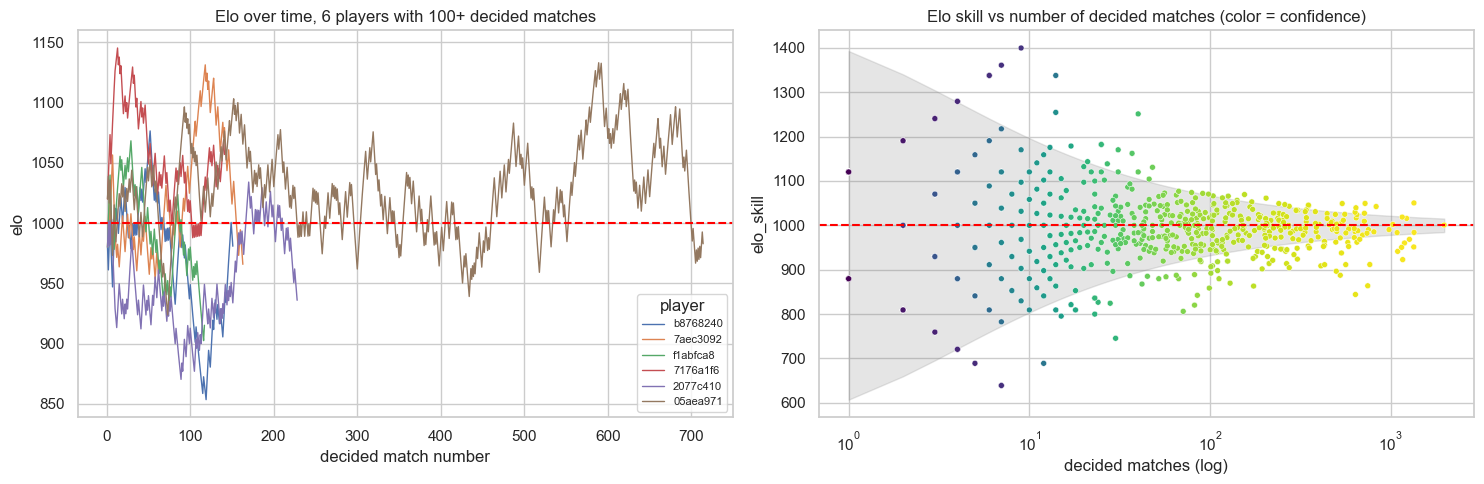

decided_bucket,players,elo_std,elo_skill_std,elo_se_median,confidence_median
cat,u32,f64,f64,f64,f64
"""1-9""",297,37.8,134.9,173.7,0.29
"""10-29""",131,58.5,102.1,84.4,0.66
"""100-299""",141,60.0,45.2,26.9,0.89
"""30-99""",177,56.7,64.3,46.5,0.81
"""300+""",94,54.0,41.3,15.2,0.94


In [ ]:
rng_elo = np.random.default_rng(1)
long_players = [pid for pid, path in elo_paths.items() if len(path) >= 100]
shown = rng_elo.choice(long_players, size=6, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for pid in shown:
    axes[0].plot(range(1, len(elo_paths[pid]) + 1), elo_paths[pid], linewidth=1, label=pid[:8])
axes[0].axhline(ELO_START, color='red', linestyle='--')
axes[0].set_xlabel('decided match number')
axes[0].set_ylabel('elo')
axes[0].set_title('Elo over time, 6 players with 100+ decided matches')
axes[0].legend(title='player', fontsize=8)

df_elo_plot = df_elo.join(df_perf.select('playerid', 'decided'), on='playerid').filter(pl.col('decided') > 0).to_pandas()
n = np.arange(1, df_elo_plot['decided'].max() + 1)
funnel = 1.96 * ELO_SCALE_SE * np.sqrt(4 / (n + 2))  # wins = losses = n / 2
axes[1].fill_between(n, ELO_START - funnel, ELO_START + funnel, color='grey', alpha=0.2)
sns.scatterplot(data=df_elo_plot, x='decided', y='elo_skill', hue='elo_confidence', palette='viridis', size=8, legend=False, ax=axes[1])
axes[1].set_xscale('log')
axes[1].axhline(ELO_START, color='red', linestyle='--')
axes[1].set_xlabel('decided matches (log)')
axes[1].set_ylabel('elo_skill')
axes[1].set_title('Elo skill vs number of decided matches (color = confidence)')
fig.tight_layout()
plt.show()

df_elo.join(df_perf.select('playerid', 'decided'), on='playerid').with_columns(
    pl.col('decided').cut([9, 29, 99, 299], labels=['1-9', '10-29', '30-99', '100-299', '300+']).alias('decided_bucket')
).group_by('decided_bucket').agg(
    pl.len().alias('players'),
    pl.col('elo').std().round(1).alias('elo_std'),
    pl.col('elo_skill').std().round(1).alias('elo_skill_std'),
    pl.col('elo_se').median().round(1).alias('elo_se_median'),
    pl.col('elo_confidence').median().round(2).alias('confidence_median'),
).sort('decided_bucket')

Observation:
- **`elo` does depend on the number of matches**: with 1-9 matches it stays close to 1000 (std 38), then spreads to 55-60 from 10 matches on and stops growing (K = 20 keeps a recency noise whatever the history). It is a **current form**, it moves over time (see the trajectories).
- `elo_skill` is the long-run level (shrunk win rate: 0.9999 correlation with win rate among 30+ matches). Its spread shrinks with the number of matches (std 135 with 1-9 matches vs 41 with 300+): **the wide spread of the small players is mostly noise**.
- Confidence grows with the matches: median 0.29 (1-9), 0.66 (10-29), 0.81 (30-99), 0.89 (100-299), 0.94 (300+); the 95% interval is about +/-170 Elo points with few matches and +/-30 with 300+.
- `elo_confidence` is a volume feature (0.45 correlation with `still_active`, 0.69 AUC active vs inactive): **not a skill signal**, to use as a weight or a filter.
- Next: use `elo_skill` only for players with a confidence of 0.8+ (about 50 decided matches: 339 players).

## 7. Assemble: one row per player

`df_players_features` holds every feature, tagged by family in `FEATURE_GROUPS`. The recency group is the one that leaks `still_active`.

In [ ]:
df_players_features: pl.DataFrame = (
    df_activity.join(df_perf, on='playerid', how='left')
    .join(df_behaviour, on='playerid', how='left')
    .join(df_modes, on='playerid', how='left')
    .join(df_social, on='playerid', how='left')
    .join(df_elo, on='playerid', how='left')
    .join(df_addiction, on='playerid', how='left')
    .with_columns(
        (pl.col('win_rate_last') - pl.col('win_rate_first')).alias('win_rate_trend'),
        (pl.col('kd_last') - pl.col('kd_first')).alias('kd_trend'),
    )
    .with_columns(
        pl.when(pl.col('matches') >= 2 * N_EDGE).then(pl.col('win_rate_trend')).alias('win_rate_trend'),
        pl.when(pl.col('matches') >= 2 * N_EDGE).then(pl.col('kd_trend')).alias('kd_trend'),
    )
    .drop('win_rate_first', 'win_rate_last', 'kd_first', 'kd_last')
    .sort('playerid')
)

TARGET: str = 'still_active'
FEATURE_GROUPS: dict[str, list[str]] = {
    'recency (leaks the target)': ['last_match', 'days_since_last_match', 'matches_last_30d', 'matches_last_90d'],
    'activity': ['matches', 'first_match', 'tenure_days', 'active_days', 'active_weeks', 'active_weeks_share', 'sessions', 'sessions_per_week',
                 'matches_per_active_day', 'matches_per_session', 'median_break_h', 'max_gap_days', 'matches_first_30d'],
    'performance': ['decided', 'wins', 'win_rate', 'matches_with_kd', 'kd_ratio', 'kills_per_match', 'deaths_per_match', 'kills_std', 'deaths_std',
                    'kills_max', 'share_zero_kill', 'share_kills_ge_deaths', 'win_rate_early', 'kd_early', 'win_rate_trend', 'kd_trend',
                    'last_result_win', 'max_win_streak', 'max_loss_streak', 'current_streak', 'elo', 'elo_peak', 'elo_skill', 'elo_se', 'elo_confidence', 'elo_low', 'elo_high'],
    'behaviour': ['stay_after_loss', 'stay_after_win', 'tilt_gap', 'share_weekend', 'share_night', 'median_hour', 'max_session_matches'],
    'modes and lobbies': [c for c in df_modes.columns if c != 'playerid'],
    'social': [c for c in df_social.columns if c != 'playerid'],
    'composite scores': ['addiction_index'],
}
grouped: list[str] = [c for cols in FEATURE_GROUPS.values() for c in cols]
assert sorted(grouped + ['playerid', TARGET]) == sorted(df_players_features.columns), set(df_players_features.columns) ^ set(grouped + ['playerid', TARGET])
assert df_players_features['playerid'].n_unique() == df_players_features.height == df_raw['playerid'].n_unique()

df_players_features = df_players_features.select('playerid', TARGET, *grouped)
df_players_features.write_parquet(OUTPUT_PATH)
print(df_players_features.shape, '->', OUTPUT_PATH)
print({group: len(cols) for group, cols in FEATURE_GROUPS.items()})
df_players_features.head(5)

(840, 72) -> player_features.parquet
{'recency (leaks the target)': 4, 'activity': 13, 'performance': 27, 'behaviour': 7, 'modes and lobbies': 13, 'social': 5, 'composite scores': 1}


playerid,still_active,last_match,days_since_last_match,matches_last_30d,matches_last_90d,matches,first_match,tenure_days,active_days,active_weeks,active_weeks_share,sessions,sessions_per_week,matches_per_active_day,matches_per_session,median_break_h,max_gap_days,matches_first_30d,decided,…,max_session_matches,share_pvp_ranked,share_pvp_unranked,share_pvp,n_modes,avg_lobby_size,share_standard_lobby,avg_teammates,win_rate_pvp,win_rate_pvp_unranked,win_rate_pvp_ranked,kd_ratio_pvp,kd_ratio_pvp_unranked,kd_ratio_pvp_ranked,unique_teammates,unique_opponents,repeat_teammate_share,repeat_opponent_share,top_teammate_share,addiction_index
str,bool,"datetime[μs, UTC]",f64,u32,u32,u32,"datetime[μs, UTC]",f64,u32,u32,f64,u32,f64,f64,f64,f64,f64,u32,u32,…,u32,f64,f64,f64,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,u32,u32,f64,f64,f64,f64
"""00229b3f-4e74-4e8d-b6ce-37df9a…",false,2025-06-29 12:56:21.419 UTC,247.040255,0,0,24,2025-03-07 16:49:44.910 UTC,113.837917,5,4,0.235294,13,0.753075,4.8,1.846154,0.79375,95.392963,19,24,…,5,0.5,0.333333,0.166667,3,10.083333,0.958333,4.0,null,0.625,0.333333,null,0.432432,0.393443,65,118,0.322917,0.032787,0.708333,32.425677
"""002bbbc5-5078-436e-ad52-e8af9b…",true,2026-03-01 17:22:08.138 UTC,1.855694,47,93,119,2025-03-07 01:39:22.080 UTC,359.654699,41,19,0.365385,76,1.450956,2.902439,1.565789,15.706111,225.194375,16,119,…,6,0.92437,0.0,0.07563,2,10.033613,0.890756,4.016807,0.444444,null,0.418182,0.96,null,0.805068,134,588,0.719665,0.015075,0.672269,34.714549
"""00460d80-da57-4551-9cdd-f292ea…",false,2026-01-22 23:13:43.175 UTC,39.611539,0,2,4,2025-03-05 07:20:53.349 UTC,323.661678,2,2,0.042553,4,0.084679,2.0,1.0,10.418056,323.171285,2,4,…,1,0.0,0.5,0.5,2,10.5,0.5,4.0,null,null,null,null,null,null,16,22,0.0,0.0,0.25,null
"""0051177e-b731-4c60-a75a-9a7e8f…",false,2025-12-01 02:39:35.614 UTC,92.468565,0,0,111,2025-05-09 01:56:44.356 UTC,206.029757,30,17,0.548387,44,1.445807,3.7,2.522727,23.1525,29.983646,34,111,…,10,0.135135,0.135135,0.72973,3,11.774775,0.414414,5.036036,0.407407,0.466667,0.6,0.547872,0.684211,0.641791,363,622,0.350626,0.023548,0.972973,65.180216
"""007775a1-5302-4c7f-a366-a3e31b…",false,2025-12-19 07:58:57.486 UTC,74.246782,0,29,402,2025-03-05 07:16:49.525 UTC,289.029248,59,17,0.404762,193,4.563738,6.813559,2.082902,1.954167,105.860185,106,401,…,9,0.950249,0.042289,0.007463,3,9.930348,0.925373,3.977612,null,0.647059,0.496063,null,1.764706,0.939975,1511,1855,0.055034,0.068307,0.00995,59.957906


## 8. Checks

Missing values per feature (a null is expected when the feature is undefined: no death, too few matches, no match in a mode...) and a sanity recomputation of a few features with plain python on random players.

In [ ]:
df_nulls: pl.DataFrame = (
    df_players_features.null_count().unpivot(variable_name='feature', value_name='nulls')
    .filter(pl.col('nulls') > 0).sort('nulls', descending=True)
    .with_columns((pl.col('nulls') / df_players_features.height).round(3).alias('share'))
)
print(df_nulls)

shape: (24, 3)
┌───────────────────────┬───────┬───────┐
│ feature               ┆ nulls ┆ share │
│ ---                   ┆ ---   ┆ ---   │
│ str                   ┆ u32   ┆ f64   │
╞═══════════════════════╪═══════╪═══════╡
│ win_rate_pvp_ranked   ┆ 514   ┆ 0.612 │
│ kd_ratio_pvp_ranked   ┆ 514   ┆ 0.612 │
│ win_rate_pvp_unranked ┆ 500   ┆ 0.595 │
│ kd_ratio_pvp_unranked ┆ 500   ┆ 0.595 │
│ win_rate_trend        ┆ 383   ┆ 0.456 │
│ kd_trend              ┆ 383   ┆ 0.456 │
│ win_rate_pvp          ┆ 369   ┆ 0.439 │
│ kd_ratio_pvp          ┆ 369   ┆ 0.439 │
│ addiction_index       ┆ 297   ┆ 0.354 │
│ tilt_gap              ┆ 175   ┆ 0.208 │
│ stay_after_win        ┆ 142   ┆ 0.169 │
│ median_break_h        ┆ 141   ┆ 0.168 │
│ stay_after_loss       ┆ 125   ┆ 0.149 │
│ kills_std             ┆ 93    ┆ 0.111 │
│ deaths_std            ┆ 93    ┆ 0.111 │
│ max_gap_days          ┆ 92    ┆ 0.11  │
│ kd_ratio              ┆ 7     ┆ 0.008 │
│ kd_early              ┆ 7     ┆ 0.008 │
│ kills_per_match  

In [ ]:
# plain python recomputation on 30 random players
rng = np.random.default_rng(0)
sample_ids = rng.choice(df_players_features['playerid'].to_numpy(), size=30, replace=False)
SESSION_GAP_S = SESSION_GAP_MIN * 60

for pid in sample_ids:
    rows = df_raw.filter(pl.col('playerid') == pid).sort('match_datetime', 'matchid').to_dicts()
    feat = df_players_features.filter(pl.col('playerid') == pid).to_dicts()[0]

    times = [r['match_datetime'] for r in rows]
    sessions = 1 + sum((b - a).total_seconds() > SESSION_GAP_S for a, b in zip(times, times[1:]))
    results = [r['victory'] for r in rows]
    # longest loss run, current streak
    best, current, previous = 0, 0, None
    for result in results:
        current = current + 1 if result == previous else 1
        previous = result
        if result == 'FALSE':
            best = max(best, current)
    last_streak = current if previous == 'TRUE' else -current if previous == 'FALSE' else 0
    teammates = {t for r in rows for t in (r['teammateid'] or '').split(',') if t}

    assert feat['matches'] == len(rows)
    assert feat['sessions'] == sessions, (pid, feat['sessions'], sessions)
    assert feat['max_loss_streak'] == best
    assert feat['current_streak'] == last_streak
    assert feat['unique_teammates'] == len(teammates)
    assert feat['active_days'] == len({t.date() for t in times})
print('python recomputation OK on', len(sample_ids), 'players')

python recomputation OK on 30 players


Observation:
- Nulls are structural, not errors: per-mode win rate / K/D (44-61% null), trends (20+ matches, 46% null), `tilt_gap` / `stay_after_*` / `median_break_h` (no loss, win or second session), `kills_std` (single match).
- The plain python recomputation matches the table on 30 random players (sessions, streaks, unique teammates, active days).

## 9. First look: link of each feature with `still_active`

Spearman correlation between each numeric feature and the target (1 = active, 0 = inactive). It is only an indication (raw, all players, noisy for players with few matches), to guide the next notebook. The recency features are shown in a different color: they are expected to be the strongest because they almost define the target.

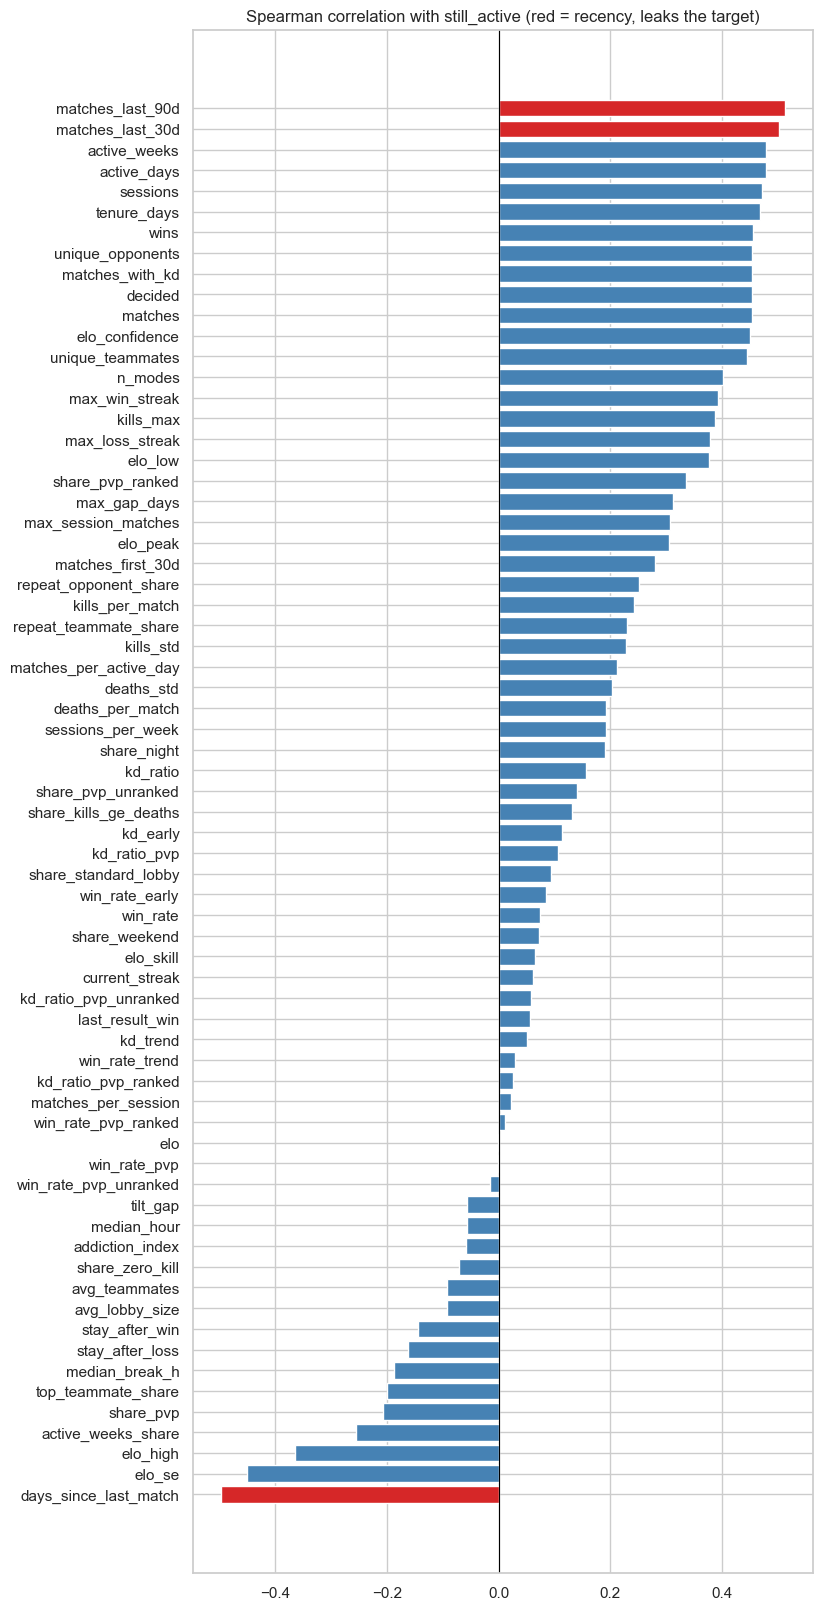

,days_since_last_match,elo_se,elo_high,active_weeks_share,share_pvp,top_teammate_share,median_break_h,stay_after_loss,stay_after_win,avg_lobby_size,...,decided,matches_with_kd,unique_opponents,wins,tenure_days,sessions,active_days,active_weeks,matches_last_30d,matches_last_90d
spearman,-0.5,-0.45,-0.36,-0.25,-0.21,-0.2,-0.19,-0.16,-0.14,-0.09,...,0.45,0.45,0.45,0.45,0.47,0.47,0.48,0.48,0.5,0.51


In [ ]:
numeric_features: list[str] = [
    c for c in grouped
    if df_players_features.schema[c].is_numeric() or df_players_features.schema[c] == pl.Boolean
]
pdf = df_players_features.select(TARGET, *numeric_features).to_pandas().astype(float)
corr = pdf.drop(columns=TARGET).corrwith(pdf[TARGET], method='spearman').dropna().sort_values()
leak = set(FEATURE_GROUPS['recency (leaks the target)'])

fig, ax = plt.subplots(figsize=(8, 0.28 * len(corr) + 1))
ax.barh(corr.index, corr.values, color=['tab:red' if c in leak else 'steelblue' for c in corr.index])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Spearman correlation with still_active (red = recency, leaks the target)')
plt.show()
corr.round(2).to_frame('spearman').T

## 10. Correlation heatmap

Spearman correlation between all numeric features and the target, ordered by feature family (recency, activity, performance, behaviour, modes, social, scores). Blocks of strong correlation show redundant features (volume features move together): pick one per block before modelling.

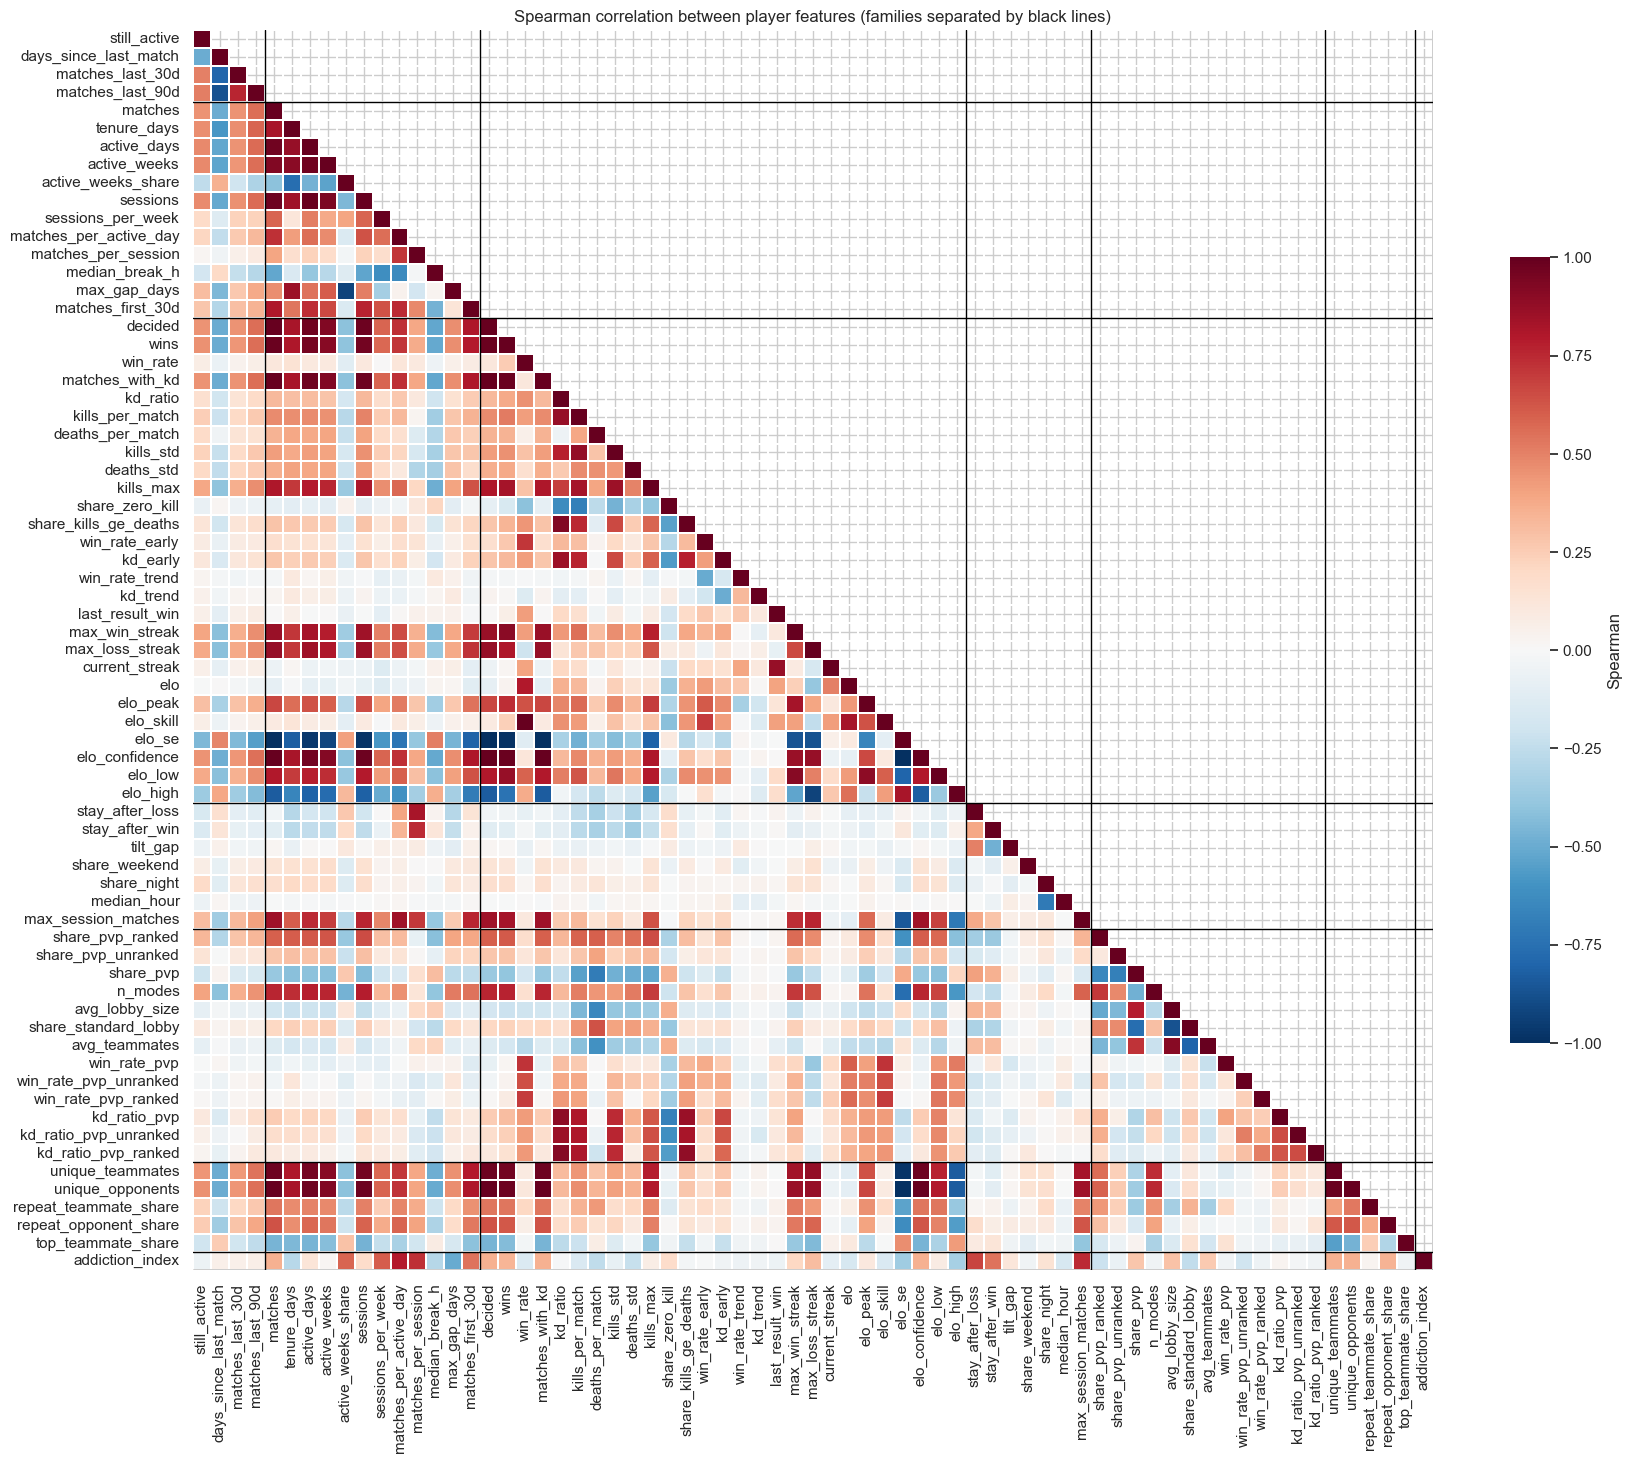

elo_confidence    elo_se             -1.00
decided           matches             1.00
matches_with_kd   matches             1.00
                  decided             1.00
elo_confidence    matches             1.00
elo_se            matches            -1.00
elo_confidence    decided             1.00
elo_se            decided            -1.00
                  matches_with_kd    -1.00
elo_confidence    matches_with_kd     1.00
unique_opponents  decided             1.00
                  matches             1.00
                  matches_with_kd     1.00
                  elo_confidence      0.99
                  elo_se             -0.99
elo_skill         win_rate            0.99
unique_opponents  unique_teammates    0.99
elo_confidence    wins                0.99
elo_se            wins               -0.99
wins              decided             0.99
                  matches             0.99
sessions          active_days         0.99
matches_with_kd   wins                0.98
unique_team

In [ ]:
ordered: list[str] = [TARGET] + [c for cols in FEATURE_GROUPS.values() for c in cols if c in numeric_features]
corr_matrix = df_players_features.select(ordered).to_pandas().astype(float).corr(method='spearman')

fig, ax = plt.subplots(figsize=(20, 17))
sns.heatmap(
    corr_matrix, mask=np.triu(np.ones_like(corr_matrix, dtype=bool), k=1), cmap='RdBu_r', center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.2, cbar_kws={'shrink': 0.6, 'label': 'Spearman'}, ax=ax,
)
# family boundaries
position = 1
for group, cols in FEATURE_GROUPS.items():
    position += len([c for c in cols if c in numeric_features])
    ax.axhline(position, color='black', linewidth=1)
    ax.axvline(position, color='black', linewidth=1)
ax.set_title('Spearman correlation between player features (families separated by black lines)')
plt.show()

# strongest feature pairs (|rho| >= 0.9) = redundant features
pairs = corr_matrix.where(np.tril(np.ones(corr_matrix.shape, dtype=bool), k=-1)).stack()
pairs[pairs.abs() >= 0.9].sort_values(key=abs, ascending=False).round(2).head(30)

Observation:
- Volume features form one block at 0.95-1.0 (`matches`, `decided`, `wins`, `matches_with_kd`, `sessions`, `active_days`, `unique_teammates`, `unique_opponents`): **redundant, keep one** (e.g. `matches`).
- `still_active` correlates with volume / lifespan (0.45-0.51) and `n_modes` (0.40), weakly with skill (K/D 0.16, win rate 0.07).
- `elo` is close to `win_rate` and partly to `kd_ratio`, and `addiction_index` is mostly independent from the other blocks.

Observation:
- `df_players_features`: **840 players x 70 features** (+ `playerid` and `still_active`), saved in `player_features.parquet`. 352 players (41.9%) are still active.
- **Strongest links with `still_active`** (Spearman): recency (`matches_last_90d` 0.51, `days_since_last_match` -0.50, leaking), then volume / lifespan (`active_weeks` 0.48, `tenure_days` 0.47, `matches` 0.45) and `n_modes` 0.40.
- **Skill is a weak signal** (K/D 0.16, win rate 0.07, Elo 0.00): who stays is explained by engagement, not by results.
- Volume features are partly a *consequence* of staying: prefer early-window features (`matches_first_30d`, `win_rate_early`, `kd_early`, mode mix).
- Next: filter on `matches` (10+: 543 players) for rate-based features, and build a first-30-days version of the table to model churn without leakage.